# **EDA Notebook**



---
## 0. Setup Environment

In [ ]:
# DO NOT MODIFY THE CODE IN THIS CELL
!pip install -q utstd

from utstd.folders import *
from utstd.ipyrenders import *

at = AtFolder(
    course_code=36106,
    assignment="AT3",
)
at.run()

import warnings
warnings.simplefilter(action='ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 59.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
hdbscan 0.8.42 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
Mounted at /content/gdrive

You can now save your data files in: /content/gdrive/MyDrive/36106/assignment/AT3/data


---
## Student Information

In [ ]:
group_name = "Group 21"
student_name = "Vishwesh Kalyam"
student_id = "25424211"


In [ ]:
# Do not modify this code
print_tile(size="h1", key='group_name', value=group_name)

In [ ]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [ ]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

### 0.a Install Additional Packages

> If you are using additional packages, you need to install them here using the command: `! pip install <package_name>`

In [ ]:
! pip install matplotlib seaborn -q


### 0.b Import Packages

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


---
## B. Data Understanding

In [ ]:
# Do not modify this code
try:
  df = pd.read_csv(at.folder_path / "customer.csv")
except Exception as e:
  print(e)

### B.1 Explore Dataset

In [ ]:
print(f"Shape: {df.shape}")
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.head()


Shape: (14275, 5)

Data types:
customer_id       object
person_id         object
store_id          object
territory_id      object
account_number    object
dtype: object

Missing values:
customer_id           0
person_id           237
store_id          13823
territory_id          0
account_number        0
dtype: int64

Duplicate rows: 3944


,customer_id,person_id,store_id,territory_id,account_number
0,4b5762b3-b7bf-4716-9bf9-5c1c9e1f375d,092707ff-4088-4416-ac86-14491f3120c2,NaN,0ad4c625-bb65-4376-8a41-0a65719b0db8,AW00019475
1,26bfba89-84b7-4b5b-9bab-caf7a2791006,fe043525-e0af-4578-a4b9-bfa7be28f4e4,NaN,25d73ad2-9e13-410b-8b0d-5f26e2b9e4f2,AW00022390
2,cf2cf4cc-fcce-4fe5-9400-78373420b525,ee25bbaf-5cdd-4ed4-92fe-7136c4e803a9,NaN,0ad4c625-bb65-4376-8a41-0a65719b0db8,AW00016320
3,83f558b8-bdab-4781-b112-55d2c275ff52,f0452f05-3690-4170-9fb0-fbf9995bbea7,NaN,2ac923e9-3043-4f5e-bae0-ad28089bf187,AW00026149
4,5edc53f4-7821-4a9b-9c27-a45dd2af713e,16c2532d-adb6-4a33-b0ea-71b87d83a904,NaN,0ad4c625-bb65-4376-8a41-0a65719b0db8,AW00021849


In [ ]:
df.describe(include="all")


,customer_id,person_id,store_id,territory_id,account_number
count,14275,14038,452,14275,14275
unique,10331,9232,160,4,9392
top,060c5593-b9c3-4c41-97bd-78040e780308,22b96ea8-51cf-4fce-b556-112654cfee06,af39eeb6-feb3-4df5-a2f1-407ecdc01998,2ac923e9-3043-4f5e-bae0-ad28089bf187,AW00019103
freq,3,4,6,5567,4


In [ ]:
dataset_insights = """
The customer dataset contains 14,275 rows and 5 columns, though 3,944 of those rows are exact duplicates which will need to be addressed before modelling. Most columns are UUID-type string identifiers acting as foreign keys to other tables, with store_id being 96.8% null, indicating the customer base is predominantly individual consumers rather than business accounts. territory_id and account_number are fully populated, while person_id has a small number of missing values (237) that are worth investigating further in the preparation stage.
"""


In [ ]:
# Do not modify this code
print_tile(size="h3", key='dataset_insights', value=dataset_insights)

---
## B.2 Explore Feature of Interest `territory_id`

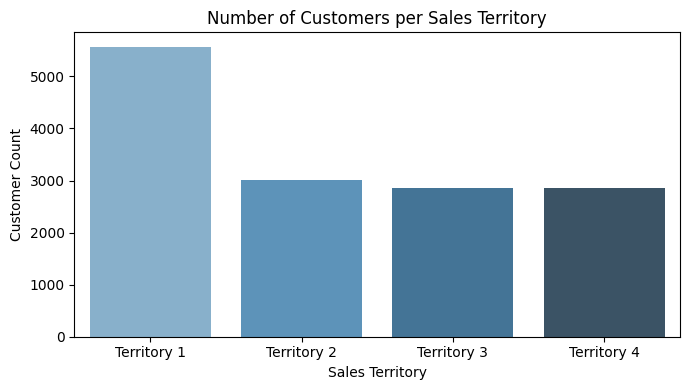

In [ ]:
territory_counts = df["territory_id"].value_counts().reset_index()
territory_counts.columns = ["territory_id", "customer_count"]
territory_counts["territory_label"] = ["Territory " + str(i+1) for i in range(len(territory_counts))]

plt.figure(figsize=(7, 4))
sns.barplot(data=territory_counts, x="territory_label", y="customer_count", palette="Blues_d")
plt.title("Number of Customers per Sales Territory")
plt.xlabel("Sales Territory")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()


In [ ]:
print("Unique territories:", df["territory_id"].nunique())


Unique territories: 4


In [ ]:
feature_1_insights = """
The territory_id column shows a noticeably uneven distribution across the four sales territories, with one territory accounting for roughly 40% of all customers while the remaining three sit between 2500 and 3,000 , this kind of geographic imbalance could influence model performance if territory is used as a feature, and may warrant encoding strategies in the preparation stage.
"""


In [ ]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

---
## B.3 Explore Feature of Interest `person_id` vs `store_id`

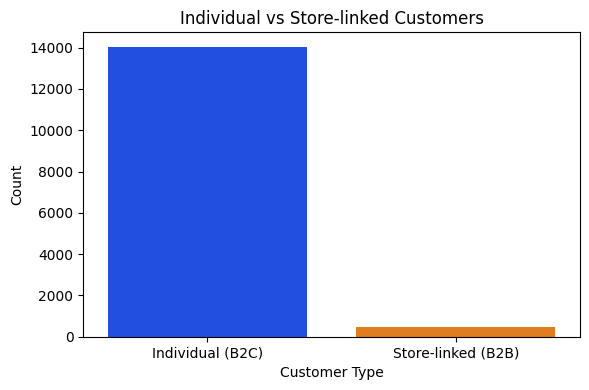

B2C: 14038 (98.3%)
B2B: 452 (3.2%)


In [ ]:
b2c = df["person_id"].notna().sum()
b2b = df["store_id"].notna().sum()

type_counts = pd.DataFrame({
    "Customer Type": ["Individual (B2C)", "Store-linked (B2B)"],
    "Count": [b2c, b2b]
})

plt.figure(figsize=(6, 4))
sns.barplot(data=type_counts, x="Customer Type", y="Count", palette="bright")
plt.title("Individual vs Store-linked Customers")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print(f"B2C: {b2c} ({b2c/len(df)*100:.1f}%)")
print(f"B2B: {b2b} ({b2b/len(df)*100:.1f}%)")


In [ ]:
print("Unique customers:", df["customer_id"].nunique())


Unique customers: 10331


In [ ]:
feature_2_insights = """
The presence of person_id versus store_id essentially distinguishes individual consumers from business/store-linked customers, around 90-95% of records have a person_id, while only 2-5% are linked to a store, suggesting the retailer operates predominantly in a B2C model with very limited B2B activity, which is an important contextual point when interpreting purchasing behaviour patterns in downstream analysis.
"""


In [ ]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

---
## B.4 Explore Feature of Interest store_id Missingness

In [ ]:
store_null = df["store_id"].isna().sum()
store_present = df["store_id"].notna().sum()

print(f"store_id present: {store_present} ({store_present/len(df)*100:.1f}%)")
print(f"store_id missing: {store_null} ({store_null/len(df)*100:.1f}%)")

both = (df["person_id"].notna() & df["store_id"].notna()).sum()
neither = (df["person_id"].isna() & df["store_id"].isna()).sum()
print(f"Customers with both: {both}")
print(f"Customers with neither: {neither}")


store_id present: 452 (3.2%)
store_id missing: 13823 (96.8%)
Customers with both: 215
Customers with neither: 0


In [ ]:
print("Null summary:")
print(df[["person_id","store_id"]].isnull().sum())


Null summary:
person_id      237
store_id     13823
dtype: int64


In [ ]:
feature_n_insights = """
The store_id column is missing for 96.8% of customers, which is not a data quality issue per se but rather a structural characteristic of the dataset - customers either have a person_id or a store_id but never both, effectively making this a mutually exclusive customer type indicator that could be converted into a simple binary feature for modelling purposes.
"""


In [ ]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)